In [6]:
%pip install scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 16.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [seaborn]m3/4 [seaborn]earn]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np

# 1. Load and Clean
df = pd.read_csv('riboflavin_features.csv')
for col in df.columns:
    if col != 'filename':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['label'])

# 2. Identify all feature columns (exclude filename and label)
all_features = df.columns.drop(['filename', 'label'])

stability_results = []

for feat in all_features:
    # Group by concentration and calculate Mean and Std for this specific feature
    group_stats = df.groupby('label')[feat].agg(['mean', 'std'])
    
    # Calculate CV for each concentration group
    # CV = (Std / Mean) * 100
    group_cvs = (group_stats['std'] / group_stats['mean'].replace(0, np.nan)) * 100
    
    # Take the average CV across all concentration levels
    avg_cv = group_cvs.mean(skipna=True)
    
    stability_results.append({'feature': feat, 'avg_cv': avg_cv})

# 3. Create a Ranking DataFrame
ranking_df = pd.DataFrame(stability_results).sort_values(by='avg_cv')

print("--- Top 30 Most Stable Features (Lowest CV) ---")
print(ranking_df.head(30).to_string(index=False))

print("\n--- Bottom 5 Most Volatile Features (Highest CV) ---")
print(ranking_df.tail(5).to_string(index=False))

--- Top 30 Most Stable Features (Lowest CV) ---
          feature      avg_cv
             skew -218.879150
      fractal_dim    1.152398
       fft_energy    1.983862
      correlation    2.410352
mean_eccentricity    4.876930
   mean_intensity   14.559116
     grid_mean_27   19.255628
     grid_mean_28   19.337301
     grid_mean_36   19.380435
     grid_mean_26   19.402984
     grid_mean_20   19.474700
     grid_mean_44   19.518720
     grid_mean_19   19.532859
     grid_mean_43   19.613962
     grid_mean_35   19.615370
     grid_mean_18   19.746660
     grid_mean_29   19.750898
    std_intensity   19.762311
     grid_mean_34   19.779403
     grid_mean_21   19.875653
     grid_mean_11   19.908133
     grid_mean_37   19.953398
     grid_mean_42   19.961799
     grid_mean_51   19.969981
     grid_mean_12   20.029497
     grid_mean_25   20.136260
     grid_mean_10   20.229258
     grid_mean_52   20.230458
     grid_mean_45   20.258434
     grid_mean_33   20.353201

--- Bottom 5 Most Vol

In [4]:
import pandas as pd
import numpy as np

# 1. Load and clean
df = pd.read_csv('riboflavin_features.csv')
for col in df.columns:
    if col != 'filename':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['label'])

# 2. Run Correlation Tests
all_features = df.columns.drop(['filename', 'label'])
results = []

for feat in all_features:
    # Drop NaNs for this specific pair
    clean_pair = df[[feat, 'label']].dropna()
    if len(clean_pair) < 2: continue
    
    p_corr = clean_pair[feat].corr(clean_pair['label'], method='pearson')
    s_corr = clean_pair[feat].corr(clean_pair['label'], method='spearman')
    
    results.append({
        'feature': feat,
        'Pearson (Linear)': p_corr,
        'Spearman (Curve)': s_corr,
        'Non-Linear Gap': abs(s_corr) - abs(p_corr)
    })

# 3. Display Results
rel_df = pd.DataFrame(results).sort_values(by='Spearman (Curve)', ascending=False, key=abs)

print("--- Top 10 Features for Formula Generation ---")
print(rel_df.head(10).to_string(index=False))

print("\n--- Features that likely need a Quadratic/Log Formula (High Gap) ---")
print(rel_df.sort_values(by='Non-Linear Gap', ascending=False).head(5).to_string(index=False))

--- Top 10 Features for Formula Generation ---
       feature  Pearson (Linear)  Spearman (Curve)  Non-Linear Gap
mean_thickness          0.115289          0.571046        0.455757
  grid_mean_29         -0.428641         -0.542636        0.113995
  grid_mean_12         -0.432501         -0.542216        0.109714
  grid_mean_44         -0.430723         -0.541975        0.111251
  grid_mean_36         -0.431290         -0.541064        0.109774
  grid_mean_20         -0.433268         -0.540269        0.107001
  grid_mean_11         -0.435333         -0.539324        0.103991
  grid_mean_21         -0.426980         -0.538650        0.111671
  grid_mean_28         -0.432928         -0.537889        0.104961
  grid_mean_43         -0.426448         -0.537317        0.110869

--- Features that likely need a Quadratic/Log Formula (High Gap) ---
       feature  Pearson (Linear)  Spearman (Curve)  Non-Linear Gap
mean_thickness          0.115289          0.571046        0.455757
 max_thickne

In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np

# 1. Select the 'Golden Trio' of features
fused_features = ['grid_mean_29', 'fractal_dim', 'mean_thickness']

# 2. Clean data (Filtering outliers at 95th percentile)
limit = df['mean_thickness'].quantile(0.95)
fused_df = df[(df['mean_thickness'] < limit)].dropna(subset=fused_features + ['label']).copy()

X = fused_df[fused_features]
y = fused_df['label']

# 3. Create Quadratic Features (Includes x^2 and interactions like Grid29 * MeanThickness)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# 4. Fit the Nonlinear Model
poly_model = LinearRegression().fit(X_poly, y)
y_pred = poly_model.predict(X_poly)
r2_poly = r2_score(y, y_pred)

# 5. Display Results
print(f"--- Quadratic Fused Model (R2: {r2_poly:.4f}) ---")
print("This model captures non-linear curves to better fit high-concentration data.")

# Create a mapping of feature names to coefficients for clarity
feature_names = poly.get_feature_names_out(fused_features)
coeffs = dict(zip(feature_names, poly_model.coef_))

print(f"\nIntercept: {poly_model.intercept_:.4f}")
print("Top 3 Influence Drivers:")
# Sort by absolute value of coefficient to see what matters most
for name in sorted(coeffs, key=lambda x: abs(coeffs[x]), reverse=True)[:3]:
    print(f"  {name}: {coeffs[name]:.4f}")

--- Quadratic Fused Model (R2: 0.5700) ---
This model captures non-linear curves to better fit high-concentration data.

Intercept: 83508.8607
Top 3 Influence Drivers:
  fractal_dim: -76212.4484
  fractal_dim^2: 17411.4076
  grid_mean_29: -91.6790


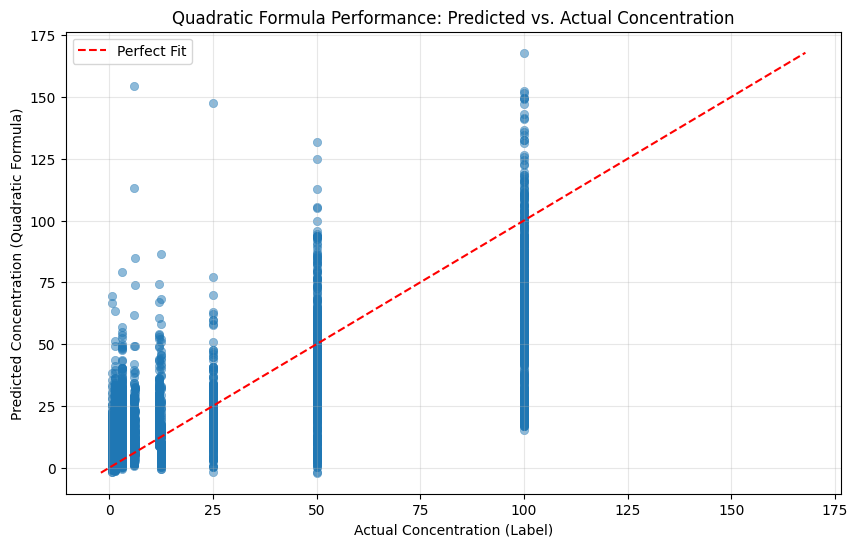

The R² value for the Quadratic formula is: 0.5700


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Prepare the features for the prediction
# Ensure we use the exact same columns used to train the poly_model
X_filtered = filtered_df[fused_features] 

# 2. Apply the Quadratic Transformation and Prediction
# 'poly' is the PolynomialFeatures object from your previous step
X_poly_filtered = poly.transform(X_filtered) 
filtered_df['predicted_conc'] = poly_model.predict(X_poly_filtered)

# 3. Visualization: Predicted vs. Actual
plt.figure(figsize=(10, 6))

# Define plot boundaries for the 1:1 line
max_val = max(filtered_df['label'].max(), filtered_df['predicted_conc'].max())
min_val = min(filtered_df['label'].min(), filtered_df['predicted_conc'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Fit')

# Scatter plot of the results
sns.scatterplot(
    data=filtered_df, 
    x='label', 
    y='predicted_conc', 
    alpha=0.5, 
    edgecolor=None
)

plt.title("Quadratic Formula Performance: Predicted vs. Actual Concentration")
plt.xlabel("Actual Concentration (Label)")
plt.ylabel("Predicted Concentration (Quadratic Formula)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Calculate the R² for the filtered set
r_square = np.corrcoef(filtered_df['label'], filtered_df['predicted_conc'])[0,1]**2
print(f"The R² value for the Quadratic formula is: {r_square:.4f}")

### Analysis
Not feasible to make linear/quadratic relation